In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM, LayerNormalization, GlobalAveragePooling1D
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

In [ ]:
data = pd.read_csv("/content/bismillah data.csv" )
data

,country,date,sector,GWh
0,Mexico,1/1/2022,Gas,493.556
1,Mexico,2/1/2022,Gas,493.653
2,Mexico,3/1/2022,Gas,494.662
3,Mexico,4/1/2022,Gas,498.657
4,Mexico,5/1/2022,Gas,499.937
...,...,...,...,...
1210,Mexico,26/04/2025,Gas,649.285
1211,Mexico,27/04/2025,Gas,651.161
1212,Mexico,28/04/2025,Gas,650.995
1213,Mexico,29/04/2025,Gas,654.125


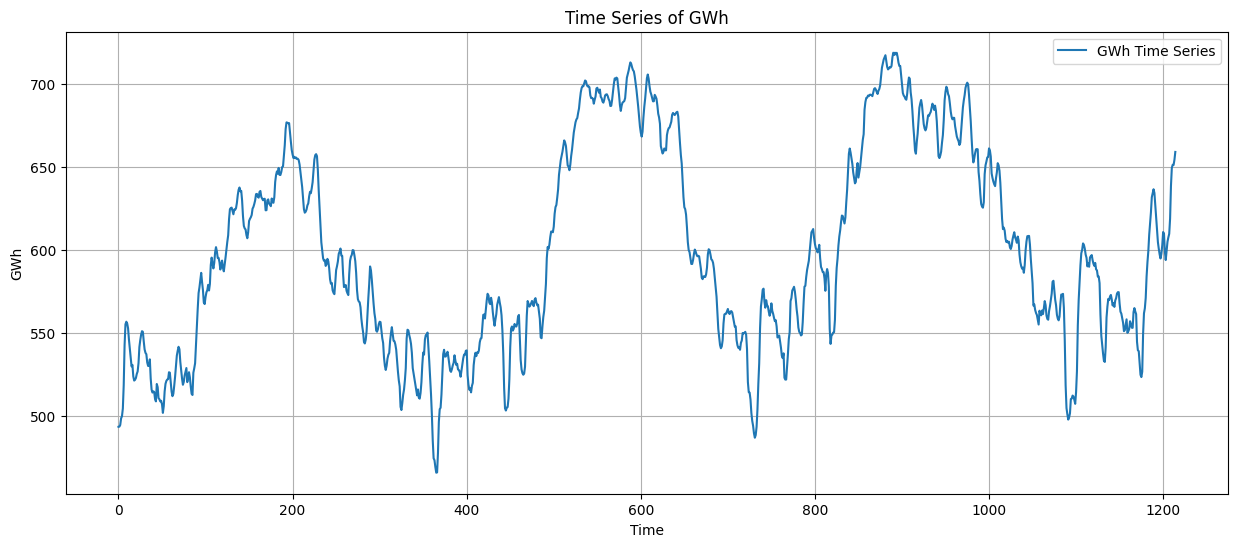

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 6))
plt.plot(data["GWh"], label='GWh Time Series')
plt.xlabel('Time')
plt.ylabel('GWh')
plt.title('Time Series of GWh')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Data preprocessing
df = data[["GWh"]].values  # Pastikan df sudah tersedia
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df)

In [ ]:
lookback_window = 30

In [ ]:
x = []
y = []
for i in tqdm(range(lookback_window, len(df_scaled))):
    x.append(df_scaled[i - lookback_window:i])
    y.append(df_scaled[i])

x = np.array(x)
y = np.array(y)
x = np.reshape(x, (x.shape[0], x.shape[1], 1))

100%|██████████| 1185/1185 [00:00<00:00, 510187.87it/s]


In [ ]:
train_size = int(len(x) * 0.8)
x_train, x_val = x[:train_size], x[train_size:]
y_train, y_val = y[:train_size], y[train_size:]

In [ ]:
def build_model_lstm_attention(hp):
    input_layer = Input(shape=(lookback_window, 1))

    # LSTM Layer
    lstm_output = tf.keras.layers.LSTM(
        units=hp.Choice('lstm_units', [16, 32, 64, 128]),
        return_sequences=False  # Changed to False for a single output prediction
    )(input_layer)

    # Output
    output_layer = Dense(1, activation='linear')(lstm_output) # Pass lstm_output here

    # Model
    model = Model(inputs=input_layer, outputs=output_layer)
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )
    return model

In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.3 MB/s eta 0:00:00


In [ ]:
from keras_tuner.tuners import RandomSearch

tuner = RandomSearch(
    build_model_lstm_attention,  # Ganti dengan fungsi build model LSTM
    objective='val_loss',       # Tujuan optimisasi
    max_trials=3,               # Jumlah percobaan
    executions_per_trial=1,     # Eksekusi per percobaan
    directory='new_dir',
    project_name='new_project'
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# EarlyStopping untuk mencegah overfitting
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

# Pencarian hyperparameter
tuner.search(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]  # Mendapatkan model terbaik
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]  # Mendapatkan hyperparameter terbaik

print("Best Hyperparameters:")
print("LSTM Units    :", best_hp.get('lstm_units'))
# print("Num Heads     :", best_hp.get('num_heads')) # Removed as not defined in the model build function
# print("Key Dim       :", best_hp.get('key_dim')) # Removed as not defined in the model build function
# print("Final Dropout :", best_hp.get('final_dropout')) # Removed as not defined in the model build function

Best Hyperparameters:
LSTM Units    : 128


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 12 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
# Training model dengan batch_size=32
history = best_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 2.4298e-04 - mae: 0.0112 - val_loss: 3.6389e-04 - val_mae: 0.0133
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 2.3305e-04 - mae: 0.0114 - val_loss: 3.5880e-04 - val_mae: 0.0133
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 2.0718e-04 - mae: 0.0105 - val_loss: 3.5933e-04 - val_mae: 0.0135
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 2.4038e-04 - mae: 0.0113 - val_loss: 3.5232e-04 - val_mae: 0.0133
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 2.2348e-04 - mae: 0.0113 - val_loss: 3.4656e-04 - val_mae: 0.0133
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 1.9878e-04 - mae: 0.0105 - val_loss: 3.4779e-04 - val_mae: 0.0134
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 1.9625e-04 - mae: 0.0106 - val_loss: 3.4321e-04 - val_mae: 0.0133
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 1.7917e-04 - mae: 0.0100 - val_loss: 3.5383e-04 - val_mae:

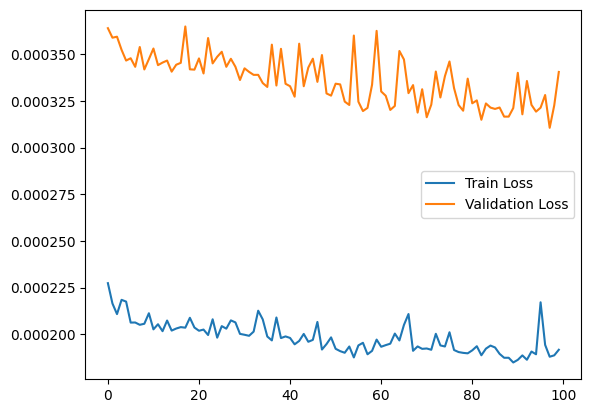

In [ ]:
# Plot learning curve
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

In [ ]:
# Prediksi dan inverse scaling
predict = best_model.predict(x_val)
predict_original_scale = scaler.inverse_transform(predict)
y_val_original_scale = scaler.inverse_transform(y_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step


In [ ]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Flatten untuk evaluasi
y_flat = y_val_original_scale.reshape(-1)
predict_flat = predict_original_scale.reshape(-1)

# Evaluasi performa
mape_value = mean_absolute_percentage_error(y_flat, predict_flat) * 100
mae = np.mean(np.abs(predict_flat - y_flat))
rmse = sqrt(mean_squared_error(y_flat, predict_flat))
r2_value = r2_score(y_flat, predict_flat)

print(f'MAPE on Testing Data: {mape_value:.4f}%')
print(f'MAE on Testing Data: {mae:.4f}')
print(f'RMSE on Testing Data: {rmse:.4f}')
print(f'R2 Score on Testing Data: {r2_value:.4f}')

MAPE on Testing Data: 1.1750%
MAE on Testing Data: 6.8954
RMSE on Testing Data: 8.5329
R2 Score on Testing Data: 0.9538


In [ ]:
# Evaluasi pada training data
predict_train = best_model.predict(x_train)
predict_train_original_scale = scaler.inverse_transform(predict_train)
y_train_original_scale = scaler.inverse_transform(y_train)

# Flatten untuk evaluasi training
y_train_flat = y_train_original_scale.reshape(-1)
predict_train_flat = predict_train_original_scale.reshape(-1)

# Evaluasi performa pada training data
mape_train = mean_absolute_percentage_error(y_train_flat, predict_train_flat) * 100
mae = np.mean(np.abs(predict_train_flat - y_train_flat))
rmse = sqrt(mean_squared_error(y_train_flat, predict_train_flat))
r2_train = r2_score(y_train_flat, predict_train_flat)

print(f'MAPE on Training Data: {mape_train:.4f}%')
print(f'MAE on Training Data: {mae:.4f}')
print(f'RMSE on Training Data: {rmse:.4f}')
print(f'R2 Score on Training Data: {r2_train:.4f}')

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
MAPE on Training Data: 0.4277%
MAE on Training Data: 2.4989
RMSE on Training Data: 3.3955
R2 Score on Training Data: 0.9972


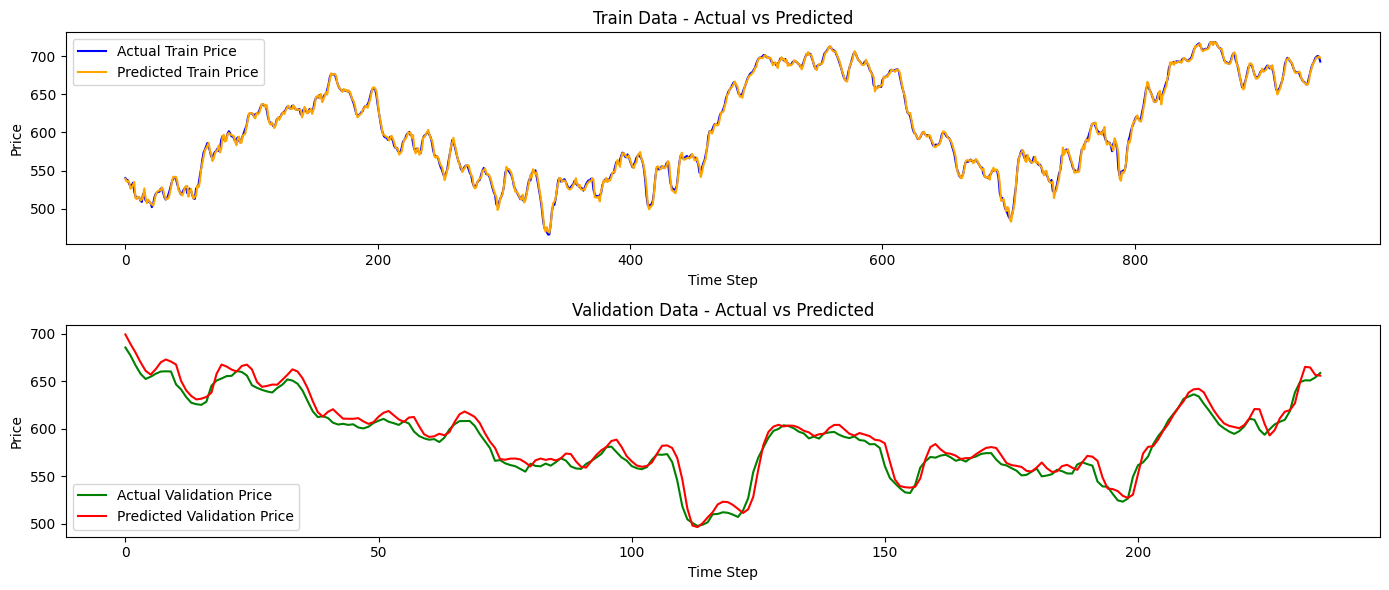

In [ ]:
# Plot hasil
plt.figure(figsize=(14, 6))

# Plot data training
plt.subplot(2, 1, 1)
plt.plot(y_train_original_scale, label='Actual Train Price', color='blue')
plt.plot(predict_train_original_scale, label='Predicted Train Price', color='orange')
plt.title('Train Data - Actual vs Predicted')
plt.xlabel('Time Step')
plt.ylabel('Price')
plt.legend()

# Plot data validasi
plt.subplot(2, 1, 2)
plt.plot(y_val_original_scale, label='Actual Validation Price', color='green')
plt.plot(predict_original_scale, label='Predicted Validation Price', color='red')
plt.title('Validation Data - Actual vs Predicted')
plt.xlabel('Time Step')
plt.ylabel('Price')
plt.legend()

plt.tight_layout()
plt.show()

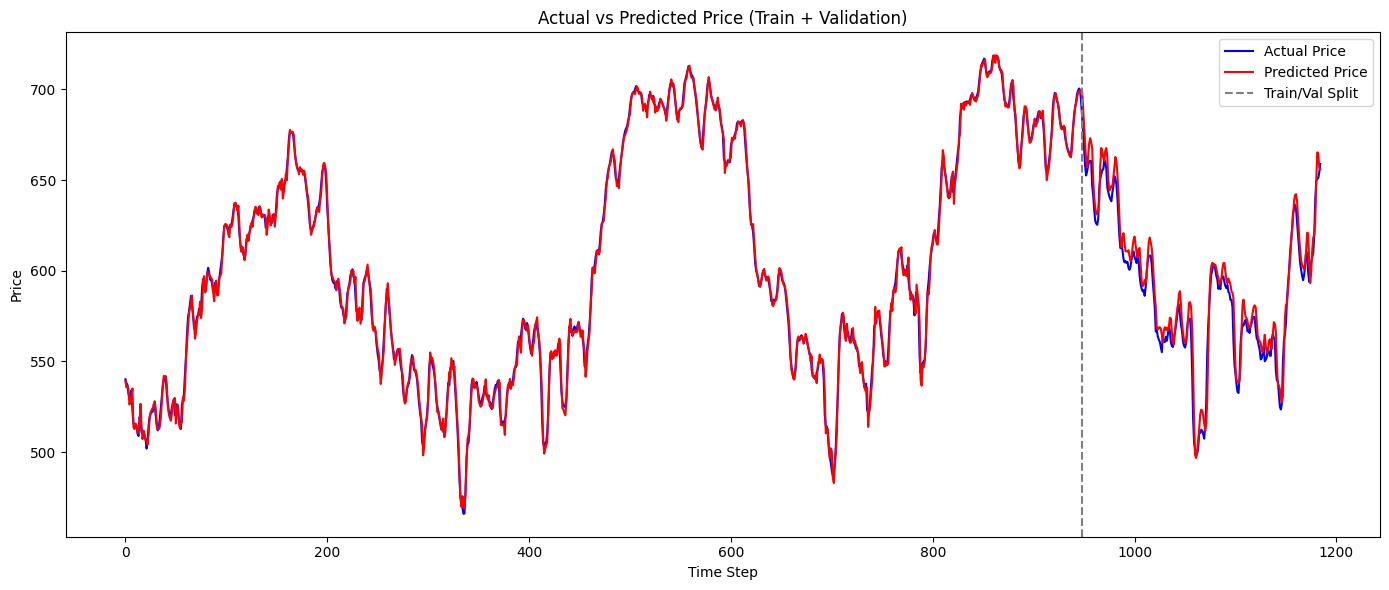

In [ ]:
full_actual = np.concatenate((y_train_original_scale, y_val_original_scale))
full_predict = np.concatenate((predict_train_original_scale, predict_original_scale))

plt.figure(figsize=(14, 6))
plt.plot(full_actual, label='Actual Price', color='blue')
plt.plot(full_predict, label='Predicted Price', color='red')
plt.axvline(x=len(y_train_original_scale), color='gray', linestyle='--', label='Train/Val Split')
plt.title('Actual vs Predicted Price (Train + Validation)')
plt.xlabel('Time Step')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━

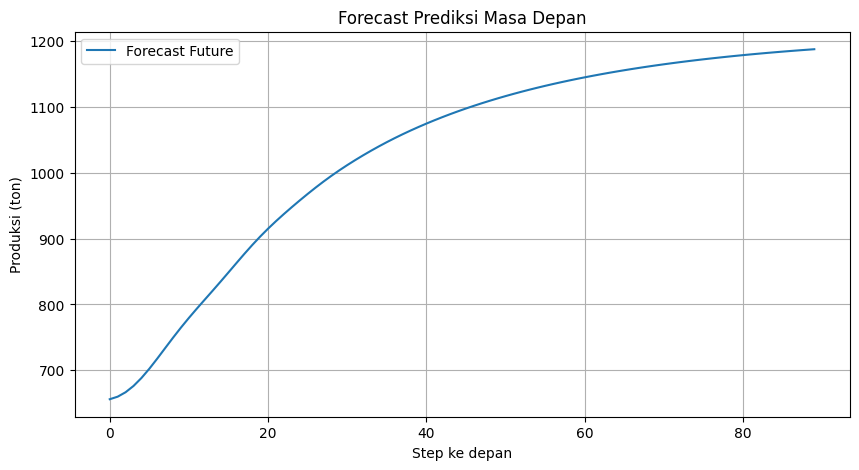

In [ ]:
n_forecast = 90  # jumlah hari ke depan
forecast_input = x_val[-1]  # ambil input terakhir dari data validasi
forecast_input = forecast_input.reshape(1, forecast_input.shape[0], 1)

future_forecast_scaled = []

for _ in range(n_forecast):
    pred = best_model.predict(forecast_input)
    future_forecast_scaled.append(pred[0, 0])

    # Perbarui input window: geser dan tambahkan prediksi terbaru
    new_input = np.append(forecast_input[0, 1:], [[pred[0, 0]]], axis=0)
    forecast_input = new_input.reshape(1, new_input.shape[0], 1)

# Inverse transform hasil prediksi
future_forecast_scaled = np.array(future_forecast_scaled).reshape(-1, 1)
future_forecast = scaler.inverse_transform(future_forecast_scaled)

# Plot prediksi masa depan
plt.figure(figsize=(10,5))
plt.plot(range(n_forecast), future_forecast, label="Forecast Future")
plt.title("Forecast Prediksi Masa Depan")
plt.xlabel("Step ke depan")
plt.ylabel("Produksi (ton)")
plt.grid(True)
plt.legend()
plt.show()

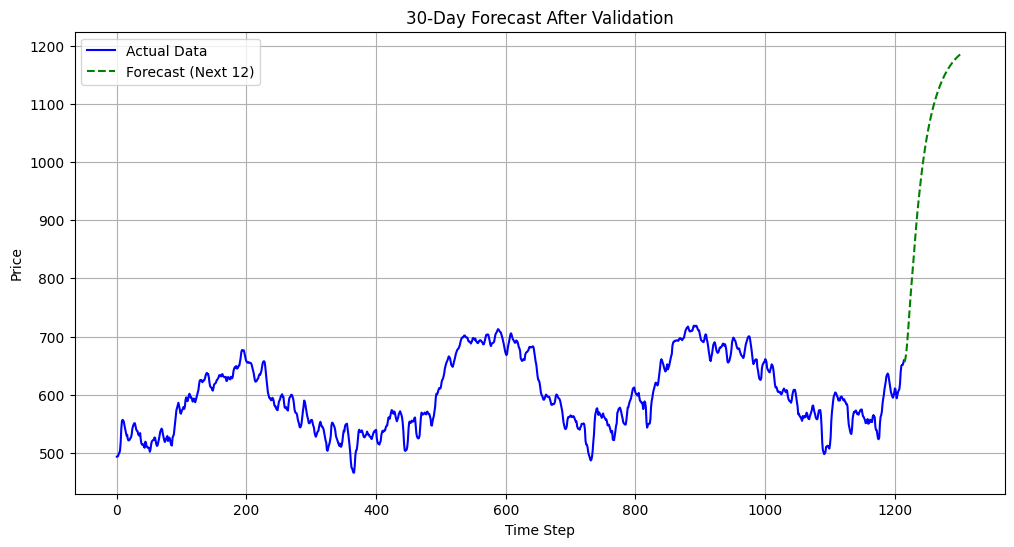

In [ ]:
# Plot hasil prediksi masa depan
plt.figure(figsize=(12, 6))

# Plot actual dari akhir validasi
plt.plot(range(len(df)), df, label='Actual Data', color='blue')

# Plot forecast ke depan setelah titik akhir data
forecast_range = range(len(df), len(df) + n_forecast)
plt.plot(forecast_range, future_forecast, label='Forecast (Next 12)', color='green', linestyle='--')

plt.title('30-Day Forecast After Validation')
plt.xlabel('Time Step')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Menyimpan model LSTM
best_model.save('best_lstm_model.keras')


In [ ]:
# Cek Model Akhir
from tensorflow.keras.models import load_model

best_model = load_model("/content/best_lstm_model.keras")

In [ ]:
# Prediksi dan inverse scaling
predict = best_model.predict(x_val)
predict_original_scale = scaler.inverse_transform(predict)
y_val_original_scale = scaler.inverse_transform(y_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step


In [ ]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Flatten untuk evaluasi
y_flat = y_val_original_scale.reshape(-1)
predict_flat = predict_original_scale.reshape(-1)

# Evaluasi performa
mape_value = mean_absolute_percentage_error(y_flat, predict_flat) * 100
mae = np.mean(np.abs(predict_flat - y_flat))
rmse = sqrt(mean_squared_error(y_flat, predict_flat))
r2_value = r2_score(y_flat, predict_flat)

print(f'MAPE on Testing Data: {mape_value:.4f}%')
print(f'MAE on Testing Data: {mae:.4f}')
print(f'RMSE on Testing Data: {rmse:.4f}')
print(f'R2 Score on Testing Data: {r2_value:.4f}')

MAPE on Testing Data: 1.1750%
MAE on Testing Data: 6.8954
RMSE on Testing Data: 8.5329
R2 Score on Testing Data: 0.9538
